
# End-to-End Supply Chain Analysis

## Business Problem

A global e-commerce company manages end-to-end supply chain operations across multiple regions. Inconsistent shipping performance and delivery delays affect operational efficiency and profitability.

## Project Objectives

- Analyze supply chain performance.
- Identify delivery and operational bottlenecks.
- Explore product and shipment patterns.
- Perform exploratory data analysis.
- Build a machine learning model to identify high-risk products.
- Generate actionable business recommendations.

## Technology Stack

Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, Jupyter Notebook.


In [1]:

%pip install pandas numpy matplotlib seaborn scikit-learn



Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.cm as cm

from warnings import filterwarnings
filterwarnings("ignore")

print("Setup complete!")

Setup complete!


In [15]:

# Set professional color theme
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("viridis")

viridis_colors = cm.viridis(np.linspace(0, 1, 5))

primary_color = viridis_colors[0]
secondary_color = viridis_colors[1]
accent_color = viridis_colors[2]
danger_color = '#800000'
neutral_color = viridis_colors[4]
custom_palette = viridis_colors

print("Professional theme set successfully!")


Professional theme set successfully!


In [16]:

# Load the supply chain dataset
df = pd.read_csv(
    'DataCoSupplyChainDataset.csv',
    encoding='latin1'
)

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [17]:

df.head()


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


Exploratory Data Analysis (EDA)

In [18]:

# Overview
print('Rows, cols:', df.shape)

print('\nColumns:')
print(df.columns.tolist())

print('\nNum duplicates:', df.duplicated().sum())

print('\nMissing values (top 20):')
print(df.isna().sum().sort_values(ascending=False).head(20))


Rows, cols: (180519, 53)

Columns:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price', 'Produc

In [19]:

columns_to_drop = [
    'Product Description',
    'Product Image',
    'Customer Email',
    'Customer Password',
    'Customer Fname',
    'Customer Lname',
    'Customer Street',
    'Customer Zipcode',
    'Order Zipcode',
    'Longitude',
    'Latitude',
    'Order Item Cardprod Id',
    'Order Item Id',
    'Order Item Discount',
    'Order Item Discount Rate',
    'Order Item Product Price',
    'Order Item Quantity',
    'Order Item Total',
    'Category Id',
    'Department Id',
    'Order Id',
    'Order Customer Id',
    'Customer Id',
    'Product Card Id',
    'Product Category Id',
    'Benefit per order',
    'Product Status',
    'Customer City',
    'Order City',
    'Order Country',
    'Order State',
    'Customer State',
    'Market'
]

# Drop only columns that actually exist
df = df.drop(
    columns=[col for col in columns_to_drop if col in df.columns]
)

print("Columns removed successfully!")
print("Remaining shape:", df.shape)



Columns removed successfully!
Remaining shape: (180519, 20)


In [20]:

# Remove cancelled orders
df = df[df['Delivery Status'] != 'Shipping canceled']

print("Cancelled orders removed!")
print(df.shape)


Cancelled orders removed!
(172765, 20)


In [21]:

# Convert date columns to datetime
for c in ['order date (DateOrders)', 'shipping date (DateOrders)']:
    df[c] = pd.to_datetime(df[c], errors='coerce', dayfirst=False)

print("Date conversion completed!")



Date conversion completed!


In [22]:

print("Rows, cols:", df.shape)

print("\nMissing values (top 5):")
print(df.isna().sum().sort_values(ascending=False).head(5))

print("\nFirst 5 rows:")
display(df.head())


Rows, cols: (172765, 20)

Missing values (top 5):
Type                             0
Days for shipping (real)         0
Days for shipment (scheduled)    0
Sales per customer               0
Delivery Status                  0
dtype: int64

First 5 rows:


,Type,Days for shipping (real),Days for shipment (scheduled),Sales per customer,Delivery Status,Late_delivery_risk,Category Name,Customer Country,Customer Segment,Department Name,order date (DateOrders),Order Item Profit Ratio,Sales,Order Profit Per Order,Order Region,Order Status,Product Name,Product Price,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,314.640015,Advance shipping,0,Sporting Goods,Puerto Rico,Consumer,Fitness,2018-01-31 22:56:00,0.29,327.75,91.250000,Southeast Asia,COMPLETE,Smart watch,327.75,2018-02-03 22:56:00,Standard Class
1,TRANSFER,5,4,311.359985,Late delivery,1,Sporting Goods,Puerto Rico,Consumer,Fitness,2018-01-13 12:27:00,-0.80,327.75,-249.089996,South Asia,PENDING,Smart watch,327.75,2018-01-18 12:27:00,Standard Class
2,CASH,4,4,309.720001,Shipping on time,0,Sporting Goods,EE. UU.,Consumer,Fitness,2018-01-13 12:06:00,-0.80,327.75,-247.779999,South Asia,CLOSED,Smart watch,327.75,2018-01-17 12:06:00,Standard Class
3,DEBIT,3,4,304.809998,Advance shipping,0,Sporting Goods,EE. UU.,Home Office,Fitness,2018-01-13 11:45:00,0.08,327.75,22.860001,Oceania,COMPLETE,Smart watch,327.75,2018-01-16 11:45:00,Standard Class
4,PAYMENT,2,4,298.250000,Advance shipping,0,Sporting Goods,Puerto Rico,Corporate,Fitness,2018-01-13 11:24:00,0.45,327.75,134.210007,Oceania,PENDING_PAYMENT,Smart watch,327.75,2018-01-15 11:24:00,Standard Class


In [23]:

# Value counts for categorical columns with low cardinality
for col in df.columns:
    if df[col].nunique() < 10:
        print(f'\n{col} value counts:')
        print(df[col].value_counts())




Type value counts:
Type
DEBIT       69295
TRANSFER    42129
PAYMENT     41725
CASH        19616
Name: count, dtype: int64

Days for shipping (real) value counts:
Days for shipping (real)
2    54205
6    27489
3    27478
4    27297
5    27003
0     4839
1     4454
Name: count, dtype: int64

Days for shipment (scheduled) value counts:
Days for shipment (scheduled)
4    103153
2     33806
1     26513
0      9293
Name: count, dtype: int64

Delivery Status value counts:
Delivery Status
Late delivery       98977
Advance shipping    41592
Shipping on time    32196
Name: count, dtype: int64

Late_delivery_risk value counts:
Late_delivery_risk
1    98977
0    73788
Name: count, dtype: int64

Customer Country value counts:
Customer Country
EE. UU.        106425
Puerto Rico     66340
Name: count, dtype: int64

Customer Segment value counts:
Customer Segment
Consumer       89420
Corporate      52528
Home Office    30817
Name: count, dtype: int64

Order Status value counts:
Order Status
COMPLETE  

In [24]:

# Calculating order processing time and delay

df['Order Processing Time'] = (
    df['shipping date (DateOrders)'] -
    df['order date (DateOrders)']
).dt.days

df['Delay'] = (
    df['Days for shipping (real)'] -
    df['Days for shipment (scheduled)']
)

df['Is_Delayed'] = df['Delay'] > 0

df['order_month'] = df['order date (DateOrders)'].dt.month
df['order_day'] = df['order date (DateOrders)'].dt.day_name()
df['order_hour'] = df['order date (DateOrders)'].dt.hour

df.describe()


,Days for shipping (real),Days for shipment (scheduled),Sales per customer,Late_delivery_risk,order date (DateOrders),Order Item Profit Ratio,Sales,Order Profit Per Order,Product Price,shipping date (DateOrders),Order Processing Time,Delay,order_month,order_hour
count,172765.000000,172765.000000,172765.000000,172765.000000,172765,172765.000000,172765.000000,172765.000000,172765.000000,172765,172765.000000,172765.000000,172765.000000,172765.000000
mean,3.498596,2.933100,183.165948,0.572900,2016-06-12 15:25:39.457991936,0.120801,203.828493,22.032360,141.278595,2016-06-16 03:25:14.452927488,3.472816,0.565496,6.235511,11.482604
min,0.000000,0.000000,7.490000,0.000000,2015-01-01 00:00:00,-2.750000,9.990000,-4274.979980,9.990000,2015-01-03 00:00:00,0.000000,-2.000000,1.000000,0.000000
25%,2.000000,2.000000,104.379997,0.000000,2015-09-21 18:01:00,0.080000,119.980003,7.030000,50.000000,2015-09-25 08:59:00,2.000000,0.000000,3.000000,5.000000
50%,3.000000,4.000000,163.990005,1.000000,2016-06-11 08:11:00,0.270000,199.919998,31.520000,59.990002,2016-06-15 03:38:00,3.000000,1.000000,6.000000,11.000000
75%,5.000000,4.000000,247.399994,1.000000,2017-02-28 21:08:00,0.360000,299.950012,64.800003,199.990005,2017-03-04 08:00:00,5.000000,1.000000,9.000000,17.000000
max,6.000000,4.000000,1939.989990,1.000000,2018-01-31 23:38:00,0.500000,1999.989990,911.799988,1999.989990,2018-02-06 22:14:00,6.000000,4.000000,12.000000,23.000000
std,1.623446,1.373405,120.141871,0.494659,NaN,0.466610,132.392520,104.355313,139.862956,NaN,1.670187,1.493242,3.405593,6.927276


In [25]:

df['Is_Delayed'].value_counts()


Is_Delayed
True     98977
False    73788
Name: count, dtype: int64

In [26]:
df.columns


Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Sales per customer', 'Delivery Status', 'Late_delivery_risk',
       'Category Name', 'Customer Country', 'Customer Segment',
       'Department Name', 'order date (DateOrders)', 'Order Item Profit Ratio',
       'Sales', 'Order Profit Per Order', 'Order Region', 'Order Status',
       'Product Name', 'Product Price', 'shipping date (DateOrders)',
       'Shipping Mode', 'Order Processing Time', 'Delay', 'Is_Delayed',
       'order_month', 'order_day', 'order_hour'],
      dtype='object')

In [27]:
positive_profit = (df['Order Profit Per Order'] > 0).sum()
negative_profit = (df['Order Profit Per Order'] < 0).sum()

print("Positive profit orders:", positive_profit)
print("Negative profit orders:", negative_profit)

Positive profit orders: 139354
Negative profit orders: 32295


In [ ]:

# Profitability distribution

profit_counts = df['Profitability Flag'].value_counts()

plt.figure(figsize=(8, 5))
profit_counts.plot(kind='bar', color=custom_palette)

plt.title('Order Profitability Distribution')
plt.xlabel('Profitability')
plt.ylabel('Number of Records')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [31]:
print(df.columns.tolist())

['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Name', 'Customer Country', 'Customer Segment', 'Department Name', 'order date (DateOrders)', 'Order Item Profit Ratio', 'Sales', 'Order Profit Per Order', 'Order Region', 'Order Status', 'Product Name', 'Product Price', 'shipping date (DateOrders)', 'Shipping Mode', 'Order Processing Time', 'Delay', 'Is_Delayed', 'order_month', 'order_day', 'order_hour']


In [32]:
df['Profitability Flag'] = np.where(
    df['Order Profit Per Order'] > 0,
    'Profit',
    np.where(
        df['Order Profit Per Order'] < 0,
        'Loss',
        'Break-even'
    )
)

print(df['Profitability Flag'].value_counts())

Profitability Flag
Profit        139354
Loss           32295
Break-even      1116
Name: count, dtype: int64


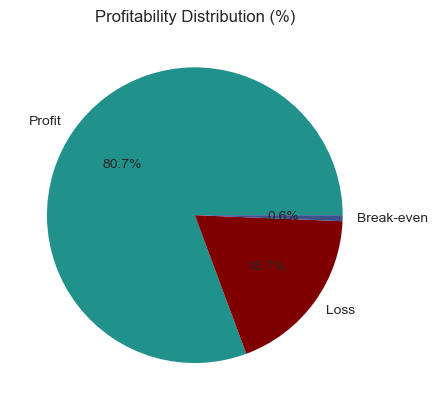

In [33]:
profit_counts = df['Profitability Flag'].value_counts(normalize=True) * 100

profit_counts.plot(
    kind='pie',
    autopct='%1.1f%%',
    colors=[accent_color, danger_color, secondary_color]
)

plt.ylabel('')
plt.title('Profitability Distribution (%)')
plt.show()

In [35]:

# Profitability vs Delivery Time Analysis

profit_metrics = (
    df.groupby('Delay')['Order Profit Per Order']
      .agg(
          mean_profit='mean',
          total_profit='sum',
          order_count='count'
      )
      .reset_index()
)

display(profit_metrics.head(10))


,Delay,mean_profit,total_profit,order_count
0,-2,23.360134,4.875961e+05,20873
1,-1,21.604769,4.476292e+05,20719
2,0,22.709146,7.311437e+05,32196
3,1,22.071211,1.279181e+06,57957
4,2,21.128491,5.821110e+05,27551
5,3,20.031412,1.356527e+05,6772
6,4,21.368783,1.431067e+05,6697


In [36]:
delay_distribution = (
    df['Delay']
    .value_counts(normalize=True)
    .sort_index() * 100
).reset_index()

In [38]:

import matplotlib.ticker as ticker


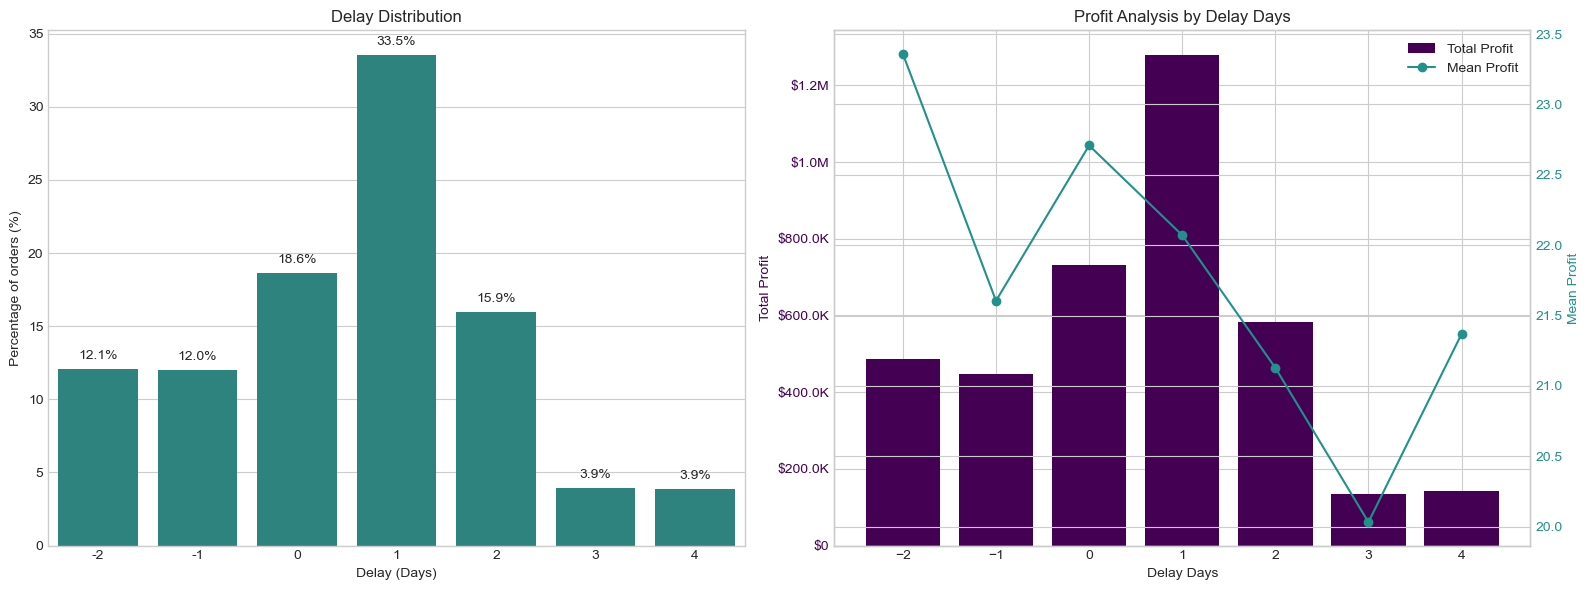

In [39]:
delay_distribution.columns = ['Delay_Days', 'Percentage']
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
# First subplot: Delay Distribution
sns.barplot(x='Delay_Days', y='Percentage', data=delay_distribution, color=accent_color, ax=ax1)
ax1.set_title('Delay Distribution')
ax1.set_xlabel('Delay (Days)')
ax1.set_ylabel('Percentage of orders (%)')
# percentage text on bars
for bar in ax1.patches:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, height + 0.5, f'{height:.1f}%', ha='center', va='bottom')
# Second subplot: Profit Analysis by Delay Days
ax2.bar(profit_metrics['Delay'], profit_metrics['total_profit'], color=primary_color, label='Total Profit')
ax2.set_ylabel('Total Profit', color=primary_color)
ax2.tick_params(axis='y', labelcolor=primary_color)
ax3 = ax2.twinx()
ax3.plot(profit_metrics['Delay'], profit_metrics['mean_profit'], color=accent_color, marker='o', label='Mean Profit')
ax3.set_ylabel('Mean Profit', color=accent_color)
ax3.tick_params(axis='y', labelcolor=accent_color)
ax2.set_xlabel('Delay Days')
ax2.set_title('Profit Analysis by Delay Days')
# Format total profit axis to K, $, M
def format_func(value, tick_number):
    if value >= 1e6:
        return f'${value/1e6:.1f}M'
    elif value >= 1e3:
        return f'${value/1e3:.1f}K'
    else:
        return f'${value:.0f}'
ax2.yaxis.set_major_formatter(ticker.FuncFormatter(format_func))
lines, labels = ax2.get_legend_handles_labels()
lines2, labels2 = ax3.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc='upper right')
plt.tight_layout()
plt.show()

Bottlenect Detection


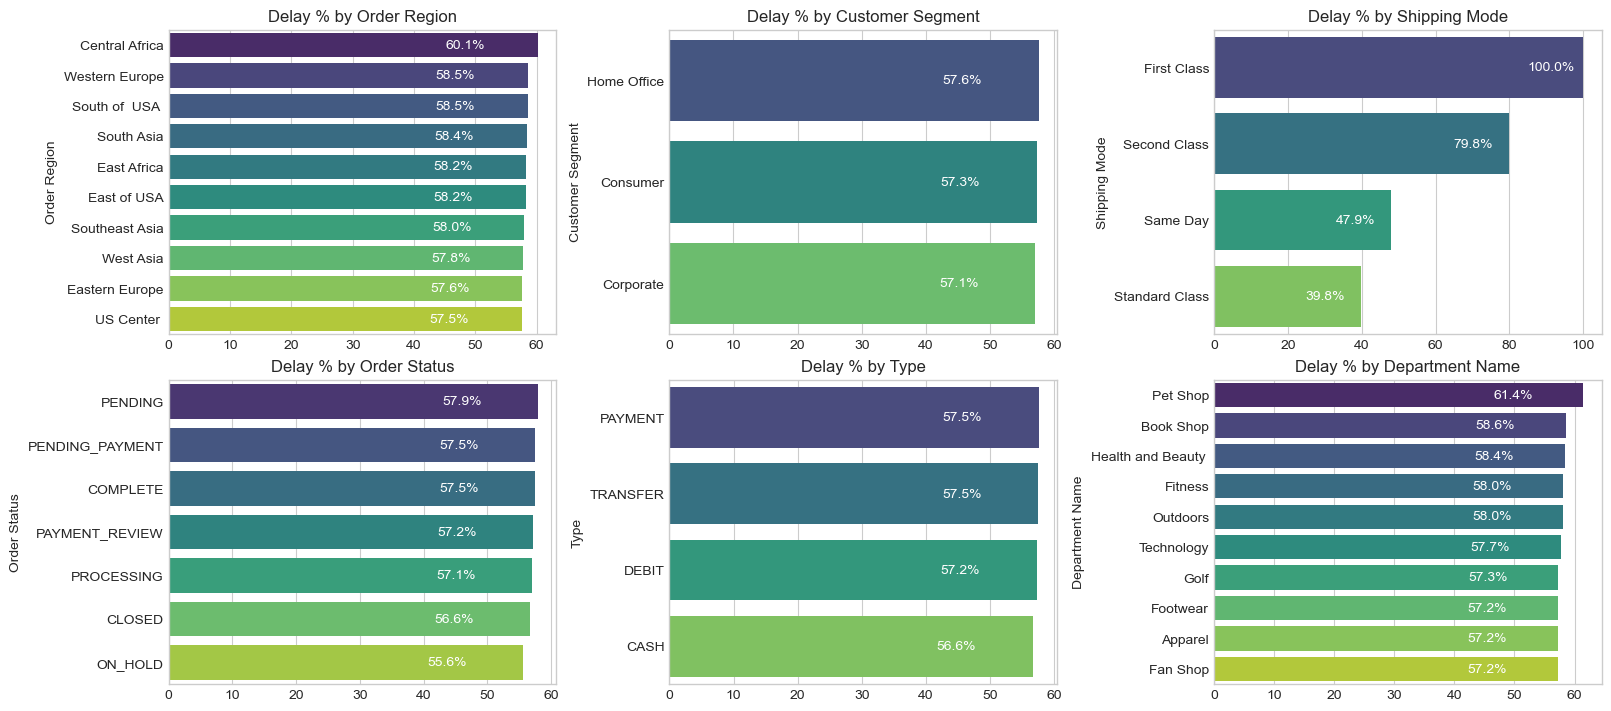

In [40]:
def compute_delay_pct_by_category(category):
    cat_df = df.groupby(category).agg(
        total_orders=('Delay', 'count'),
        late_orders=('Is_Delayed', 'sum')
    ).reset_index()
    cat_df['delay_pct'] = (cat_df['late_orders'] / cat_df['total_orders']) * 100
    cat_df = cat_df.sort_values('delay_pct', ascending=False).head(10)
    return cat_df
categories = ['Order Region', 'Customer Segment', 'Shipping Mode', 'Order Status', 'Type', 'Department Name']
fig, axes = plt.subplots(2, 3, figsize=(16, 7), constrained_layout=True)
axes = axes.flatten()
for ax, category in zip(axes, categories):
    cat_df = compute_delay_pct_by_category(category)
    sns.barplot(
        data=cat_df,
        x='delay_pct',
        y=category,
        ax=ax,
        palette='viridis'
    )
    ax.set_title(f'Delay % by {category}')
    ax.set_xlabel('')
    ax.set_ylabel(category)
    for i, row in cat_df.reset_index().iterrows():
        ax.text(row['delay_pct'] - 15, i, f"{row['delay_pct']:.1f}%", va='center', fontsize=10, color='white')
plt.show()

Root cause analysis

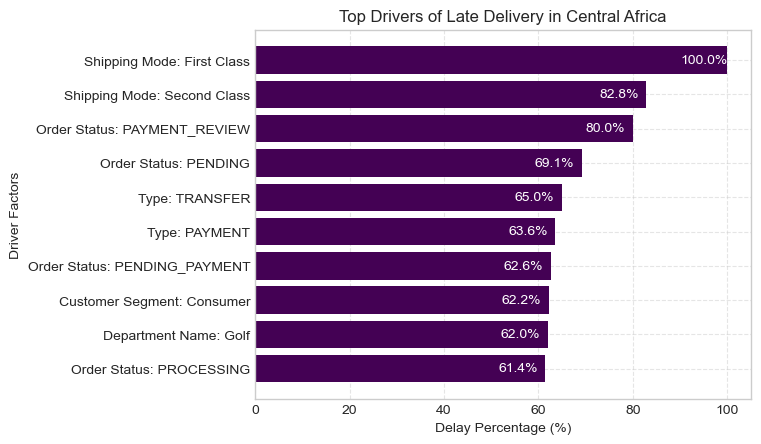

In [41]:
def top_drivers_for_region(region):
    df_region = df[df['Order Region'] == region].copy()
    drivers = ['Shipping Mode', 'Customer Segment', 'Department Name', 'Type', 'Order Status']
    all_factors = []
    for factor in drivers:
        temp = (
            df_region.groupby(factor)
            .agg(
                total_orders=('Delay', 'count'),
                late_orders=('Is_Delayed', 'sum'),
                avg_delay=('Delay', 'mean')
            )
            .reset_index()
        )
        temp['delay_pct'] = (temp['late_orders'] / temp['total_orders']) * 100
        temp['Driver'] = factor
        temp['Factor_Level'] = factor + ": " + temp[factor].astype(str)
        all_factors.append(temp[['Driver', 'Factor_Level', 'delay_pct', 'avg_delay', 'total_orders']])
    # Combine all drivers
    final_df = pd.concat(all_factors)
    # Top 10 drivers
    top_factors = final_df.sort_values('delay_pct', ascending=False).head(10)
    plt.figure()
    bars = plt.barh(top_factors['Factor_Level'], top_factors['delay_pct'], color=primary_color)
    plt.xlabel('Delay Percentage (%)')
    plt.ylabel('Driver Factors')
    plt.title(f'Top Drivers of Late Delivery in {region}')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.gca().invert_yaxis()
    for bar in bars:
        width = bar.get_width()
        plt.text(width - 10, bar.get_y() + bar.get_height()/2, f'{width:.1f}%', va='center', fontsize=10, color='white')
    plt.show()
top_drivers_for_region('Central Africa')

Time based analysis

In [43]:
delay_by_month = (
    df.groupby('order_month')['Is_Delayed']
    .mean()
    .reset_index()
)
delay_by_month['delay_pct'] = delay_by_month['Is_Delayed'] * 100
delay_by_day = (
    df.groupby('order_day')['Is_Delayed']
    .mean()
    .reset_index()
)
delay_by_day['delay_pct'] = delay_by_day['Is_Delayed'] * 100
delay_by_hour = (
    df.groupby('order_hour')['Is_Delayed']
    .mean()
    .reset_index()
)
delay_by_hour['delay_pct'] = delay_by_hour['Is_Delayed'] * 100

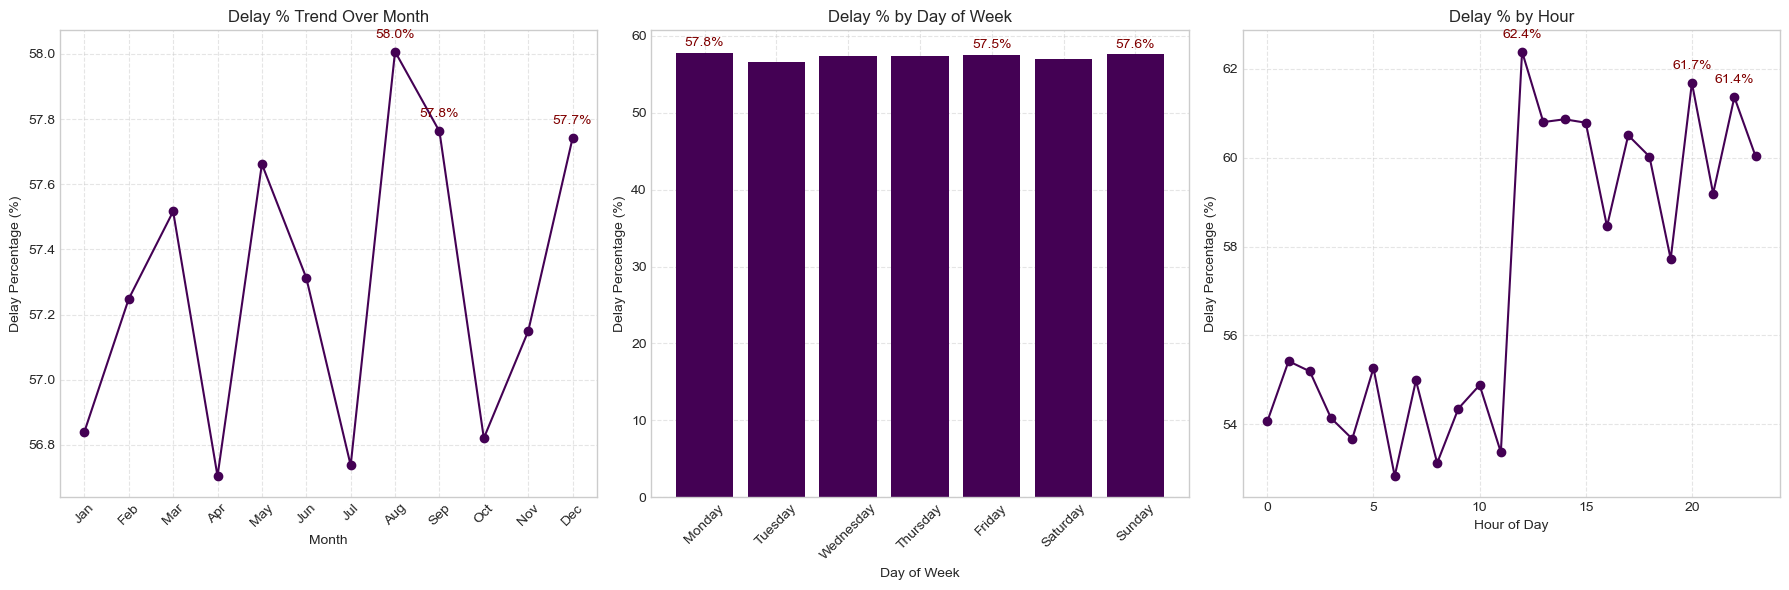

In [44]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))
# Subplot 1: Delay % Trend Over Month
ax1.plot(delay_by_month['order_month'], delay_by_month['delay_pct'], marker='o', color=primary_color)
ax1.set_xticks(range(1, 13))
ax1.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'], rotation=45)
ax1.set_xlabel('Month')
ax1.set_ylabel('Delay Percentage (%)')
ax1.set_title('Delay % Trend Over Month')
ax1.grid(True, linestyle='--', alpha=0.5)
# Annotate top 3 highest bars
top3_month = delay_by_month.nlargest(3, 'delay_pct')
for _, row in top3_month.iterrows():
    ax1.annotate(f"{row['delay_pct']:.1f}%", (row['order_month'], row['delay_pct']), textcoords="offset points", xytext=(0, 10), ha='center', fontsize=10, color=danger_color)
# Subplot 2: Delay % by Day of Week
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
delay_by_day['order_day'] = pd.Categorical(delay_by_day['order_day'], categories=day_order, ordered=True)
delay_by_day = delay_by_day.sort_values('order_day')
ax2.bar(delay_by_day['order_day'], delay_by_day['delay_pct'], color=primary_color)
ax2.set_xticklabels(delay_by_day['order_day'], rotation=45)
ax2.set_xlabel('Day of Week')
ax2.set_ylabel('Delay Percentage (%)')
ax2.set_title('Delay % by Day of Week')
ax2.grid(True, linestyle='--', alpha=0.5)
# Annotate top 3 highest bars
top3_day = delay_by_day.nlargest(3, 'delay_pct')
for _, row in top3_day.iterrows():
    height = row['delay_pct']
    ax2.text(row['order_day'], height + 0.5, f"{height:.1f}%", ha='center', va='bottom', fontsize=10, color=danger_color)
# Subplot 3: Delay % by Hour
ax3.plot(delay_by_hour['order_hour'], delay_by_hour['delay_pct'], marker='o', color=primary_color)
ax3.set_xlabel('Hour of Day')
ax3.set_ylabel('Delay Percentage (%)')
ax3.set_title('Delay % by Hour')
ax3.grid(True, linestyle='--', alpha=0.5)
# Annotate top 3 highest bars
top3_hour = delay_by_hour.nlargest(3, 'delay_pct')
for _, row in top3_hour.iterrows():
    ax3.annotate(f"{row['delay_pct']:.1f}%", (row['order_hour'], row['delay_pct']), textcoords="offset points", xytext=(0, 10), ha='center', fontsize=10, color=danger_color)
plt.tight_layout()
plt.show()


Machine Learning Modeling

In [51]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report
from sklearn.ensemble import RandomForestClassifier
from collections import Counter
from imblearn.over_sampling import SMOTE


In [47]:
[col for col in df.columns if 'late' in col.lower()]

['Late_delivery_risk']

In [48]:
[col for col in df.columns if 'late' in col.lower()]

['Late_delivery_risk']

In [49]:
print(df.columns.tolist())

['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Name', 'Customer Country', 'Customer Segment', 'Department Name', 'order date (DateOrders)', 'Order Item Profit Ratio', 'Sales', 'Order Profit Per Order', 'Order Region', 'Order Status', 'Product Name', 'Product Price', 'shipping date (DateOrders)', 'Shipping Mode', 'Order Processing Time', 'Delay', 'Is_Delayed', 'order_month', 'order_day', 'order_hour', 'Profitability Flag']


In [52]:
X = df[['Type', 'Days for shipment (scheduled)',
        'Category Name', 'Customer Segment',
        'Department Name', 'Order Region',
        'Shipping Mode', 'order_month', 'order_hour']]

y = df['Late_delivery_risk']

In [53]:
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
print("Categorical columns:", cat_cols)

Categorical columns: ['Type', 'Category Name', 'Customer Segment', 'Department Name', 'Order Region', 'Shipping Mode']


In [55]:

# Machine Learning - Feature Selection

X = df[
    [
        'Type',
        'Days for shipment (scheduled)',
        'Category Name',
        'Customer Segment',
        'Department Name',
        'Order Region',
        'Shipping Mode',
        'order_month',
        'order_hour'
    ]
].copy()

y = df['Late_delivery_risk']

print("Features selected successfully!")
print("X shape:", X.shape)
print("y shape:", y.shape)


Features selected successfully!
X shape: (172765, 9)
y shape: (172765,)


In [56]:

# Frequency encoding

cat_cols = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Categorical columns:", cat_cols)

for col in cat_cols:
    freq = X[col].value_counts(normalize=True)
    X[col + '_freq'] = X[col].map(freq)

X_encoded = X.drop(columns=cat_cols)

print("Shape after encoding:", X_encoded.shape)


Categorical columns: ['Type', 'Category Name', 'Customer Segment', 'Department Name', 'Order Region', 'Shipping Mode']
Shape after encoding: (172765, 9)


In [57]:

# Split the dataset into training and testing sets

X = X_encoded

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (138212, 9)
Testing features: (34553, 9)
Training target: (138212,)
Testing target: (34553,)


In [58]:

from collections import Counter

print("Before balancing (train):", Counter(y_train))


Before balancing (train): Counter({1: 79182, 0: 59030})


In [59]:
%pip install imbalanced-learn

Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.



In [60]:

from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_bal, y_train_bal = smote.fit_resample(
    X_train,
    y_train
)

print("After balancing (train):", Counter(y_train_bal))


After balancing (train): Counter({0: 79182, 1: 79182})


In [61]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    classification_report
)

def evaluate_model(y_true, y_pred, model_name):
    print(f"\n--- {model_name} ---")
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 2))
    print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 2))
    print("Recall:", round(recall_score(y_true, y_pred, zero_division=0), 2))
    print("\nClassification Report:\n")
    print(classification_report(y_true, y_pred, zero_division=0))


In [63]:

from sklearn.ensemble import RandomForestClassifier

rf_model_balanced = RandomForestClassifier(random_state=42)

rf_model_balanced.fit(X_train_bal, y_train_bal)

y_pred_rf_balanced = rf_model_balanced.predict(X_test)

evaluate_model(
    y_test,
    y_pred_rf_balanced,
    "Random Forest Classifier"
)



--- Random Forest Classifier ---
Accuracy: 0.74
Precision: 0.79
Recall: 0.75

Classification Report:

              precision    recall  f1-score   support

           0       0.68      0.73      0.70     14758
           1       0.79      0.75      0.77     19795

    accuracy                           0.74     34553
   macro avg       0.73      0.74      0.73     34553
weighted avg       0.74      0.74      0.74     34553



order_hour                       0.243371
Days for shipment (scheduled)    0.164983
order_month                      0.130411
Order Region_freq                0.128937
Shipping Mode_freq               0.125665
Category Name_freq               0.088433
Customer Segment_freq            0.041869
Type_freq                        0.041709
Department Name_freq             0.034622
dtype: float64


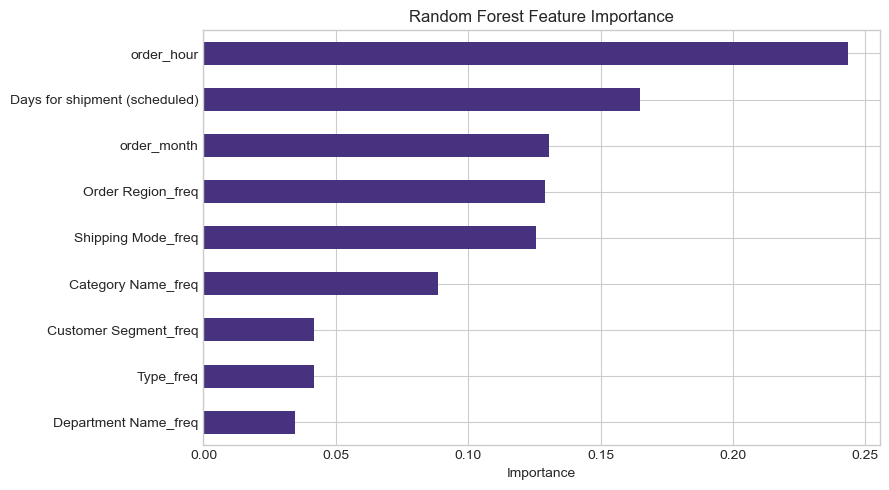

In [64]:

import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.Series(
    rf_model_balanced.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(feature_importance)

feature_importance.plot(kind='barh', figsize=(9, 5))
plt.title('Random Forest Feature Importance')
plt.xlabel('Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()
